# Diseño y preparación de datos NoSQL: SeizeIT2

**Maestría en Ciencia de Datos**  
**Materia:** Bases de Datos para Ciencia de Datos  
**Proyecto:** Diseño, preparación y análisis de una base de datos NoSQL a partir de SeizeIT2

## 1. Introducción

La epilepsia es una enfermedad neurológica caracterizada por la presencia de crisis epilépticas. Durante el monitoreo de pacientes con esta enfermedad se generan diferentes tipos de información, como registros de actividad cerebral, cardiaca, muscular y movimiento, además de anotaciones sobre los eventos que ocurren durante las grabaciones.

El conjunto de datos SeizeIT2 contiene registros obtenidos mediante dispositivos portátiles de monitoreo en personas con epilepsia focal. Debido a que la información se encuentra distribuida en diferentes archivos y formatos, resulta necesario organizarla para facilitar su consulta y posterior análisis.

En este proyecto se utiliza MongoDB como gestor de bases de datos NoSQL para almacenar información de los participantes, metadatos de las grabaciones y anotaciones de eventos. La preparación y carga de datos se realiza mediante Python.

## 2. Objetivo del proyecto

Diseñar e implementar una base de datos NoSQL en MongoDB a partir del conjunto de datos SeizeIT2, mediante la selección, limpieza, transformación y organización de la información, para facilitar su consulta y análisis exploratorio.

## 3. Fuente de datos

**Nombre:** SeizeIT2: Wearable Dataset of Patients With Focal Epilepsy.

**Repositorio:** OpenNeuro.

**Identificador DOI:** https://doi.org/10.18112/openneuro.ds005873.v1.1.0

SeizeIT2 es un conjunto de datos de investigación que contiene registros fisiológicos de personas con epilepsia focal, obtenidos mediante dispositivos portátiles. Incluye señales de electroencefalografía (EEG), electrocardiografía (ECG), electromiografía (EMG) y movimiento (MOV), así como anotaciones de eventos clínicos.

La información sigue una organización basada en BIDS (*Brain Imaging Data Structure*), que permite identificar participantes, sesiones, modalidades y segmentos de grabación.

### 3.1 Archivos utilizados

| Formato | Contenido | Uso en el proyecto |
|---|---|---|
| TSV | Información de participantes y anotaciones de eventos. | Construcción de las colecciones `participantes` y `eventos`. |
| JSON | Metadatos técnicos y descripción de variables. | Construcción de la colección `grabaciones`. |
| EDF | Mediciones fisiológicas registradas por los sensores. | Identificación y referencia de los archivos originales. |

En esta etapa, los archivos EDF se conservan en su ubicación original. La base de datos almacena sus rutas y metadatos, pero no incorpora directamente las muestras de las señales fisiológicas.

### 3.2 Justificación de la fuente

Se seleccionó SeizeIT2 porque contiene información real de pacientes con epilepsia focal y registros de distintas modalidades fisiológicas. Además, cuenta con documentación técnica y anotaciones de crisis que permiten relacionar las grabaciones con los eventos identificados durante el monitoreo.

La disponibilidad de diferentes tipos de archivos hace pertinente el uso de una base de datos NoSQL para organizar la información y facilitar su recuperación mediante consultas.

### 3.3 Alcance de los datos utilizados

Para el desarrollo del proyecto se trabaja con los archivos disponibles localmente, correspondientes a 43 participantes. Se identificaron 6,710 registros de metadatos de grabaciones y 1,888 anotaciones de eventos.

Estos conteos corresponden a la información procesada para este proyecto y no necesariamente a la totalidad del conjunto de datos publicado en OpenNeuro.

## 4. Diccionario de datos

El diccionario de datos permite identificar y describir los atributos que conforman las colecciones de MongoDB, así como sus tipos de datos y su función dentro del proyecto.

La base de datos se organiza en tres colecciones:

- **`participantes`:** contiene información general de los pacientes.
- **`grabaciones`:** almacena los metadatos técnicos y las rutas de los archivos de señales fisiológicas.
- **`eventos`:** contiene las anotaciones de los eventos identificados durante el monitoreo.

Para elaborar el diccionario se revisan los campos almacenados en cada colección, sus tipos de datos y la presencia de valores nulos.

In [5]:
from pymongo import MongoClient

# Conexión a MongoDB
cliente = MongoClient(
    "mongodb://localhost:27017",
    serverSelectionTimeoutMS=5000
)

# Seleccionar la base de datos
db = cliente["SeizeIT2_NoSQL"]

# Comprobar conexión
cliente.admin.command("ping")

print("Conexión establecida correctamente")

Conexión establecida correctamente


In [6]:
from collections import defaultdict
from IPython.display import display
import pandas as pd

def obtener_diccionario(coleccion):
    informacion = defaultdict(lambda: {
        "tipos": set(),
        "nulos": 0,
        "presentes": 0
    })

    total = db[coleccion].count_documents({})

    for documento in db[coleccion].find():
        for campo, valor in documento.items():
            if campo == "_id":
                continue

            informacion[campo]["presentes"] += 1

            if valor is None:
                informacion[campo]["nulos"] += 1
            else:
                informacion[campo]["tipos"].add(
                    type(valor).__name__
                )

    filas = []

    for campo, datos in sorted(informacion.items()):
        filas.append({
            "Atributo": campo,
            "Tipo de dato": ", ".join(sorted(datos["tipos"])) or "Sin valores",
            "Valores nulos": datos["nulos"] + total - datos["presentes"]
        })

    return pd.DataFrame(filas)


for nombre in ["participantes", "grabaciones", "eventos"]:
    print(f"\nDICCIONARIO: {nombre.upper()}")
    display(obtener_diccionario(nombre))


DICCIONARIO: PARTICIPANTES


,Atributo,Tipo de dato,Valores nulos
0,participant_id,str,0
1,sex,str,0



DICCIONARIO: GRABACIONES


,Atributo,Tipo de dato,Valores nulos
0,channel_count,int,0
1,edf_path,str,0
2,json_path,str,0
3,metadata,dict,0
4,modality,str,0
5,montage,str,0
6,participant_id,str,0
7,placement,str,0
8,recording_duration,float,0
9,recording_type,str,0



DICCIONARIO: EVENTOS


,Atributo,Tipo de dato,Valores nulos
0,channels,Sin valores,1888
1,confidence,Sin valores,1888
2,dateTime,str,0
3,duration,float,0
4,eventType,str,0
5,event_index,int,0
6,lateralization,str,1626
7,localization,str,1626
8,onset,float,0
9,participant_id,str,0


In [7]:
for nombre in ["participantes", "grabaciones", "eventos"]:
    print(f"\nCOLECCIÓN: {nombre.upper()}")

    campos = obtener_diccionario(nombre)["Atributo"].tolist()

    print(", ".join(campos))


COLECCIÓN: PARTICIPANTES
participant_id, sex

COLECCIÓN: GRABACIONES
channel_count, edf_path, json_path, metadata, modality, montage, participant_id, placement, recording_duration, recording_type, run, sampling_frequency, session, task

COLECCIÓN: EVENTOS
channels, confidence, dateTime, duration, eventType, event_index, lateralization, localization, onset, participant_id, recordingDuration, run, session, source_file, vigilance


### 4.1 Descripción de los atributos

A continuación, se describe el significado de los atributos almacenados en las tres colecciones. Los tipos de datos y los valores nulos se presentan en las tablas generadas mediante Python en la sección anterior.

#### Colección `participantes`

Esta colección contiene información general de los participantes incluidos en los archivos procesados.

| Atributo | Descripción |
|---|---|
| `participant_id` | Identificador del participante dentro del conjunto de datos. |
| `sex` | Sexo del participante, según la información disponible en el archivo original. |

#### Colección `grabaciones`

Esta colección contiene los metadatos de los archivos de señales fisiológicas. Cada documento representa un archivo de una modalidad de registro.

| Atributo | Descripción |
|---|---|
| `participant_id` | Identificador del participante al que pertenece la grabación. |
| `session` | Identificador de la sesión de monitoreo. |
| `run` | Identificador del segmento de grabación dentro de la sesión. |
| `modality` | Modalidad de registro: EEG, ECG, EMG o MOV. |
| `task` | Tarea o condición de registro indicada en los metadatos. |
| `sampling_frequency` | Frecuencia de muestreo de la señal, cuando está disponible. |
| `channel_count` | Número de canales registrados. |
| `montage` | Configuración o disposición de los canales o electrodos. |
| `placement` | Ubicación de los sensores o electrodos. |
| `recording_type` | Tipo de registro indicado en los metadatos. |
| `recording_duration` | Duración de la grabación, cuando está disponible. |
| `edf_path` | Ruta relativa del archivo EDF que contiene las mediciones fisiológicas. |
| `json_path` | Ruta relativa del archivo JSON asociado a la grabación. |
| `metadata` | Documento anidado que conserva los metadatos originales del archivo JSON. |

#### Colección `eventos`

Esta colección contiene las anotaciones registradas durante el monitoreo. Cada documento representa una anotación individual.

| Atributo | Descripción |
|---|---|
| `participant_id` | Identificador del participante al que corresponde el evento. |
| `session` | Sesión de monitoreo asociada al evento. |
| `run` | Segmento de grabación en el que se registró el evento. |
| `event_index` | Número consecutivo asignado al evento dentro de su archivo de origen. |
| `onset` | Tiempo de inicio del evento, expresado en segundos desde el comienzo del segmento. |
| `duration` | Duración del evento, expresada en segundos. |
| `eventType` | Código que identifica el tipo de evento anotado. |
| `lateralization` | Información sobre la lateralización del evento, cuando está disponible. |
| `localization` | Información sobre la localización del evento, cuando está disponible. |
| `vigilance` | Estado de vigilancia registrado para el evento, cuando está disponible. |
| `confidence` | Información sobre la confianza de la anotación, cuando está disponible. |
| `channels` | Canales asociados al evento, cuando están especificados. |
| `dateTime` | Valor de fecha y hora incluido en el archivo original; no se asume que corresponda a la fecha clínica real. |
| `recordingDuration` | Duración total del segmento de grabación, expresada en segundos. |
| `source_file` | Ruta relativa del archivo TSV del que se obtuvo el evento. |

### 4.2 Identificación y relación entre documentos

En MongoDB, cada documento tiene un identificador interno `_id`, generado automáticamente.

Adicionalmente, se utilizan atributos del conjunto de datos para identificar los registros y establecer relaciones lógicas entre colecciones.

- En `participantes`, el atributo `participant_id` identifica a cada participante.
- En `grabaciones`, la combinación de `participant_id`, `session`, `run` y `modality` identifica un archivo de una modalidad.
- En `eventos`, la combinación de `participant_id`, `session`, `run` y `event_index` identifica una anotación.

Los atributos `participant_id`, `session` y `run` permiten relacionar las anotaciones de eventos con los segmentos de grabación correspondientes.

Estas relaciones se comprueban mediante código Python, ya que MongoDB no aplica automáticamente restricciones de claves foráneas entre las colecciones.

## 5. Diseño del modelo NoSQL

Para organizar la información de SeizeIT2 se utilizó MongoDB, un sistema de bases de datos NoSQL orientado a documentos.

Se diseñaron tres colecciones: `participantes`, `grabaciones` y `eventos`. Esta separación permite administrar los datos generales de los participantes, los metadatos de los archivos fisiológicos y las anotaciones clínicas sin duplicar innecesariamente la información.

### 5.1 Estructura de las colecciones

**Colección `participantes`**

Almacena un documento por participante, identificado mediante `participant_id`. Contiene la información general disponible, como el sexo.

**Colección `grabaciones`**

Almacena un documento por archivo de una modalidad fisiológica. Incluye los identificadores del participante, sesión y segmento, así como información técnica de la grabación y las rutas de sus archivos.

Se conserva el contenido original del archivo JSON dentro del atributo `metadata`, aprovechando la posibilidad de MongoDB de almacenar documentos anidados.

**Colección `eventos`**

Almacena las anotaciones extraídas de los archivos TSV. Incluye el tipo de evento, su tiempo de inicio, duración y otras características disponibles.

Cada evento se relaciona con un participante y un segmento de grabación mediante los atributos `participant_id`, `session` y `run`.

### 5.2 Relaciones entre las colecciones

Las relaciones son lógicas y se establecen mediante identificadores compartidos.

- Un participante puede tener múltiples grabaciones.
- Un participante puede tener múltiples eventos anotados.
- Un segmento de monitoreo puede tener archivos de distintas modalidades fisiológicas.
- Un segmento puede tener una o varias anotaciones de eventos, o ninguna.

Los eventos se relacionan con los segmentos de grabación, no con una modalidad individual. Por ejemplo, una crisis epiléptica anotada para el paciente identificado como `sub-083`, durante la sesión `ses-01` y el segmento de grabación `run-32`, puede relacionarse con los archivos de señales fisiológicas disponibles para ese mismo segmento.

### 5.3 Justificación del modelo

Se eligió un modelo basado en colecciones separadas para facilitar las consultas sobre participantes, grabaciones y eventos, evitando repetir todos los metadatos de los archivos en cada anotación.

La estructura documental de MongoDB también permite conservar los metadatos originales en objetos anidados, incluso cuando los archivos JSON contienen atributos distintos según la modalidad fisiológica.

Se utilizan índices únicos compuestos para identificar las grabaciones y los eventos, lo que contribuye a evitar duplicados cuando se ejecuta nuevamente el proceso de carga.

### 5.4 Validación de relaciones

Después de la carga inicial, se comprobó que los eventos almacenados tuvieran un participante existente y al menos una grabación correspondiente al mismo participante, sesión y segmento.

Los resultados fueron:

| Validación | Resultado |
|---|---:|
| Eventos sin participante asociado | 0 |
| Eventos sin grabación asociada | 0 |

Estos resultados indican que los 1,888 eventos almacenados tienen relaciones válidas con las otras colecciones, según los identificadores utilizados.

## 6. Limpieza y calidad de los datos

La limpieza de datos tiene como finalidad identificar registros duplicados, valores faltantes e inconsistencias que puedan afectar la calidad de la información almacenada.

Para este proyecto se revisan las tres colecciones de MongoDB: `participantes`, `grabaciones` y `eventos`.

El proceso considera la identificación de duplicados mediante los atributos que distinguen cada documento, la revisión de valores nulos y la comprobación de inconsistencias en los registros de eventos.

Los archivos originales de SeizeIT2 se conservan sin modificaciones. Las transformaciones necesarias se realizan durante la preparación y carga de los documentos en MongoDB.

### 6.1 Revisión de registros duplicados

Para identificar posibles duplicados se utilizan las siguientes combinaciones de atributos:

| Colección | Atributos utilizados |
|---|---|
| `participantes` | `participant_id` |
| `grabaciones` | `participant_id`, `session`, `run`, `modality` |
| `eventos` | `participant_id`, `session`, `run`, `event_index` |

Estas combinaciones permiten comprobar si existen varios documentos que representan el mismo registro.

In [8]:
ids = [
    documento["participant_id"]
    for documento in db["participantes"].find(
        {}, {"participant_id": 1}
    )
]

print("Participantes registrados:", len(ids))
print("Identificadores diferentes:", len(set(ids)))
print("Duplicados encontrados:", len(ids) - len(set(ids)))

Participantes registrados: 43
Identificadores diferentes: 43
Duplicados encontrados: 0


### 6.2 Revisión de valores nulos

Se revisaron los documentos de las tres colecciones para identificar atributos con valores nulos o ausentes.

Esta revisión permite distinguir entre información faltante que podría afectar el análisis y campos que no necesariamente contienen datos para todos los registros.

Los valores nulos se analizan considerando el significado de cada atributo, evitando eliminar registros o sustituir valores sin una justificación.

In [9]:
import pandas as pd
from IPython.display import display

resultados_nulos = []

for nombre in ["participantes", "grabaciones", "eventos"]:
    total = db[nombre].count_documents({})

    # Obtener los atributos existentes en la colección
    campos = set()

    for documento in db[nombre].find({}, {"_id": 0}):
        campos.update(documento.keys())

    for campo in sorted(campos):
        cantidad = db[nombre].count_documents({
            campo: None
        })

        if cantidad > 0:
            resultados_nulos.append({
                "Colección": nombre,
                "Atributo": campo,
                "Valores nulos o ausentes": cantidad,
                "Porcentaje (%)": round(
                    cantidad / total * 100, 2
                )
            })

tabla_nulos = pd.DataFrame(resultados_nulos)

if tabla_nulos.empty:
    print("No se encontraron valores nulos.")
else:
    display(tabla_nulos)

,Colección,Atributo,Valores nulos o ausentes,Porcentaje (%)
0,eventos,channels,1888,100.00
1,eventos,confidence,1888,100.00
2,eventos,lateralization,1626,86.12
3,eventos,localization,1626,86.12
4,eventos,vigilance,1626,86.12


#### Resultados de la revisión de valores nulos

La revisión identificó valores nulos únicamente en la colección `eventos`. Las colecciones `participantes` y `grabaciones` no presentaron valores nulos o ausentes en los atributos revisados.

Para interpretar estos resultados es importante considerar que la colección `eventos` contiene diferentes tipos de anotaciones:

- **`bckg` (background):** corresponde a periodos de actividad de fondo, sin una crisis epiléptica anotada.
- **`impd` (impedance):** corresponde a anotaciones relacionadas con la impedancia de los electrodos.
- **`sz_` (seizure):** identifica eventos de crisis epilépticas.

Los atributos `lateralization`, `localization` y `vigilance` presentan 1,626 valores nulos (86.12 %). Estos corresponden a los 1,549 registros `bckg` y los 77 registros `impd`.

Esta ausencia de información no se considera necesariamente un error, porque los atributos mencionados describen características clínicas que pueden estar asociadas a las crisis epilépticas y no tienen por qué estar disponibles en otros tipos de anotaciones. En cambio, los 262 registros de crisis contienen información en estos campos.

Por otra parte, `channels` y `confidence` presentan valores nulos en los 1,888 documentos (100 %), debido a que los archivos originales contienen `n/a`. En estos casos, los datos no permiten recuperar información para dichos atributos.

#### Tratamiento de los valores nulos

Durante la preparación y carga de los datos, los valores `n/a` presentes en los archivos originales se transformaron a `None` mediante la función `obtener_eventos()` del archivo `main.py`. Esto permitió representar de manera consistente los valores faltantes en MongoDB.

No se eliminaron documentos con valores nulos, por lo que se conservaron las anotaciones de actividad de fondo (`bckg`), impedancia (`impd`) y crisis epilépticas (`sz_`).

Tampoco se realizó imputación de valores, debido a que no se cuenta con información suficiente para sustituirlos sin introducir datos artificiales.

Los atributos `channels` y `confidence` permanecen almacenados en la base de datos, aunque presentan valores nulos en todos los documentos. Debido a esta ausencia de información, se propone excluirlos de los análisis posteriores que requieran valores de estos atributos.

Por lo tanto, el tratamiento aplicado consistió en normalizar la representación de los valores faltantes y conservar los registros originales, sin eliminar ni sustituir información.

### 6.3 Identificación de inconsistencias

Se revisaron posibles inconsistencias en los documentos almacenados en MongoDB, principalmente en la colección `eventos`.

La revisión considera los siguientes aspectos:

- **Identificadores:** registros sin participante, sesión o segmento (`run`).
- **Tiempos:** eventos con inicio negativo, duración igual o menor que cero, o cuyo tiempo de finalización supera la duración de la grabación.
- **Tipos de eventos:** anotaciones sin una clasificación en el atributo `eventType`.

Estas verificaciones permiten identificar posibles problemas que podrían afectar la delimitación temporal de los eventos y los análisis posteriores.

In [10]:
coleccion = db["eventos"]

resultados = {
    "Sin identificador de participante":
        coleccion.count_documents({"participant_id": None}),

    "Sin sesión":
        coleccion.count_documents({"session": None}),

    "Sin segmento (run)":
        coleccion.count_documents({"run": None}),

    "Sin tipo de evento":
        coleccion.count_documents({"eventType": None}),

    "Inicio negativo":
        coleccion.count_documents({"onset": {"$lt": 0}}),

    "Duración igual o menor que cero":
        coleccion.count_documents({"duration": {"$lte": 0}})
}

# Comprobar si los eventos terminan después de la grabación
fuera_de_rango = list(coleccion.aggregate([
    {
        "$project": {
            "fin_evento": {"$add": ["$onset", "$duration"]},
            "recordingDuration": 1
        }
    },
    {
        "$match": {
            "$expr": {
                "$gt": ["$fin_evento", "$recordingDuration"]
            }
        }
    },
    {"$count": "total"}
]))

resultados["Evento fuera de la duración de grabación"] = (
    fuera_de_rango[0]["total"] if fuera_de_rango else 0
)

tabla_inconsistencias = pd.DataFrame(
    resultados.items(),
    columns=["Validación", "Registros encontrados"]
)

display(tabla_inconsistencias)

,Validación,Registros encontrados
0,Sin identificador de participante,0
1,Sin sesión,0
2,Sin segmento (run),0
3,Sin tipo de evento,0
4,Inicio negativo,0
5,Duración igual o menor que cero,3
6,Evento fuera de la duración de grabación,0


In [11]:
eventos_revision = list(
    db["eventos"].find(
        {"duration": {"$lte": 0}},
        {
            "_id": 0,
            "participant_id": 1,
            "session": 1,
            "run": 1,
            "eventType": 1,
            "onset": 1,
            "duration": 1,
            "recordingDuration": 1
        }
    )
)

display(pd.DataFrame(eventos_revision))

,participant_id,run,session,duration,eventType,onset,recordingDuration
0,sub-103,run-06,ses-01,0.0,impd,5511.0,65427.0
1,sub-115,run-48,ses-01,0.0,impd,1198.0,14024.0
2,sub-115,run-50,ses-01,0.0,impd,1211.0,17696.0


#### Resultados de la identificación de inconsistencias

La revisión de los 1,888 documentos de la colección `eventos` mostró que todos cuentan con identificador de participante, sesión, segmento (`run`) y tipo de evento.

No se encontraron tiempos de inicio negativos ni eventos cuyo tiempo de finalización supere la duración de la grabación.

Se identificaron tres registros con duración igual a cero, correspondientes a:

- `sub-103`, `ses-01`, `run-06`.
- `sub-115`, `ses-01`, `run-48`.
- `sub-115`, `ses-01`, `run-50`.

Los tres registros están clasificados como `impd`, es decir, anotaciones relacionadas con la impedancia de los electrodos.

Debido a que estas anotaciones podrían representar eventos puntuales, una duración de cero no necesariamente indica un error. Además, ninguno de los tres registros corresponde a una crisis epiléptica.

Por esta razón, se decidió conservarlos sin modificar su duración. En los análisis posteriores que requieran intervalos temporales de duración positiva, estos registros deberán tratarse de manera diferenciada.

En general, las validaciones realizadas no identificaron inconsistencias que requieran modificar los documentos almacenados en MongoDB.

### 6.4 Tratamiento y decisiones de limpieza

A partir de la revisión de duplicados, valores nulos e inconsistencias, se identificaron las siguientes acciones y decisiones para conservar la calidad de los datos.

| Aspecto | Tratamiento o decisión |
|---|---|
| Registros duplicados | Se utilizaron operaciones de actualización e inserción (`upsert`) para evitar cargar nuevamente los mismos registros. Además, se establecieron índices únicos en las colecciones `grabaciones` y `eventos`. |
| Valores faltantes | Los valores `n/a` de los archivos originales se transformaron a `None` durante la carga a MongoDB. |
| Conservación de registros | No se eliminaron documentos por presentar valores nulos, ya que algunos campos no contienen información para determinados tipos de anotaciones. |
| Imputación | No se sustituyeron valores faltantes por estimaciones, para evitar introducir información artificial. |
| Duraciones iguales a cero | Se conservaron los tres registros identificados, debido a que corresponden a anotaciones de impedancia (`impd`) y no a crisis epilépticas. |
| Identificadores y tiempos | No fue necesario realizar correcciones, ya que no se encontraron identificadores faltantes, inicios negativos ni eventos fuera de la duración de las grabaciones. |

Las transformaciones aplicadas durante la carga se encuentran implementadas en el archivo `codigo/main.py`, mientras que las consultas de validación se documentan en este notebook.

En general, el proceso permitió identificar y documentar las características de los datos sin alterar las anotaciones originales. Se conservaron los registros que podrían resultar útiles para los análisis posteriores, especialmente para distinguir las crisis epilépticas de otros tipos de eventos.

## 7. Preparación y transformación de datos

Los archivos originales de SeizeIT2 se encuentran organizados por participante, sesión y tipo de registro. Para facilitar su consulta y análisis, se desarrolló un procedimiento en Python que permite extraer y organizar la información antes de almacenarla en MongoDB.

### 7.1 Extracción de información

Se utilizaron tres tipos de archivos:

- **TSV:** contienen información de los participantes y anotaciones de eventos, incluyendo los tiempos de inicio, duración y tipo de evento.
- **JSON:** proporcionan metadatos de las grabaciones, como la frecuencia de muestreo y otras características de las señales.
- **EDF:** contienen las señales fisiológicas registradas por los dispositivos.

En esta etapa no se extrajeron las muestras de las señales fisiológicas de los archivos EDF. Se conservaron sus rutas para permitir su localización y procesamiento posterior.

### 7.2 Transformación de los datos

Para organizar la información se realizaron las siguientes transformaciones:

| Transformación | Descripción |
|---|---|
| Identificación de participantes | Se obtuvieron los identificadores de los participantes y sus datos disponibles. |
| Identificación de grabaciones | Se extrajeron los identificadores de participante, sesión, segmento (`run`) y modalidad de registro. |
| Integración de metadatos | Se incorporó la información de los archivos JSON en el atributo `metadata` de cada grabación. |
| Asociación con archivos EDF | Se identificaron las rutas de los archivos que contienen las señales fisiológicas. |
| Organización de eventos | Se transformaron las filas de los archivos `events.tsv` en documentos individuales. |
| Conversión de tipos | Los atributos `onset`, `duration` y `recordingDuration` se convirtieron a valores numéricos de tipo `float`. |
| Normalización de valores faltantes | Los valores `n/a`, `na` y las cadenas vacías se representaron como `None`. |
| Identificación de eventos | Se incorporó `event_index` para distinguir las anotaciones pertenecientes a un mismo segmento. |

### 7.3 Estructura de los datos preparados

Como resultado, la información quedó organizada en tres conjuntos de documentos:

- `participantes`: información general de los participantes.
- `grabaciones`: características de los registros fisiológicos, metadatos y rutas de archivos.
- `eventos`: anotaciones temporales de actividad de fondo, impedancia y crisis epilépticas.

Esta organización permite consultar los eventos por participante, sesión y segmento, así como identificar las grabaciones relacionadas.

La preparación se implementó en el archivo `codigo/main.py`, mediante funciones que procesan los archivos originales y construyen los documentos que posteriormente se cargan en MongoDB.

### 7.4 Alcance de la preparación

En esta primera etapa se prepararon los metadatos y las anotaciones de eventos, pero no se procesaron directamente las señales fisiológicas almacenadas en los archivos EDF.

Por lo tanto, la base de datos permite identificar las grabaciones y localizar los eventos de crisis, pero todavía no contiene valores de las señales EEG, ECG, EMG o movimiento que permitan analizar cambios fisiológicos previos a las crisis.

## 8. Carga inicial de datos en MongoDB

La carga inicial se realizó mediante el archivo `codigo/main.py`, utilizando la biblioteca `pymongo` para establecer la conexión con MongoDB.

El procedimiento utiliza operaciones `upsert`, que permiten insertar documentos nuevos o actualizar los existentes según sus identificadores. Esto evita que se dupliquen registros al ejecutar nuevamente el programa.

Para comprobar la carga, se consultó el número de documentos almacenados en cada colección.

In [12]:
conteos = {
    "participantes": db["participantes"].count_documents({}),
    "grabaciones": db["grabaciones"].count_documents({}),
    "eventos": db["eventos"].count_documents({})
}

display(pd.DataFrame(
    conteos.items(),
    columns=["Colección", "Documentos cargados"]
))

,Colección,Documentos cargados
0,participantes,43
1,grabaciones,6710
2,eventos,1888


### 8.1 Verificación de la carga

La consulta confirmó que se almacenaron 43 documentos en `participantes`, 6,710 en `grabaciones` y 1,888 en `eventos`.

Adicionalmente, se verificó que no existieran eventos sin un participante registrado ni eventos sin una grabación asociada. Ambas validaciones obtuvieron cero registros.

También se comprobó que una segunda ejecución del programa no insertara documentos duplicados.

Estos resultados permiten confirmar que la carga inicial se realizó correctamente y que las relaciones entre los documentos se conservaron.

## 9. Código Python funcional y reproducibilidad

El procesamiento y la carga de datos se implementaron en Python mediante el archivo `codigo/main.py`.

Este programa permite leer los archivos originales de SeizeIT2, preparar los documentos y almacenarlos en MongoDB.

### 9.1 Funciones principales

| Función | Descripción |
|---|---|
| `obtener_participantes()` | Identifica los participantes disponibles en el conjunto de datos. |
| `leer_participantes()` | Extrae la información de los participantes. |
| `obtener_grabaciones()` | Obtiene las grabaciones y sus metadatos. |
| `obtener_eventos()` | Lee y prepara las anotaciones de eventos. |
| `cargar_participantes()` | Inserta o actualiza los documentos de participantes. |
| `cargar_grabaciones()` | Inserta o actualiza los documentos de grabaciones. |
| `cargar_eventos()` | Inserta o actualiza los documentos de eventos. |
| `validar_relaciones()` | Comprueba las relaciones entre participantes, grabaciones y eventos. |
| `main()` | Coordina la ejecución del procedimiento completo. |

### 9.2 Configuración de la fuente de datos

El programa permite establecer la ubicación de los archivos originales mediante la variable de entorno `SEIZEIT2_DATA_DIR`.

Si esta variable no se define, el programa busca los archivos en la carpeta `datos` del proyecto.

De esta manera, no es necesario modificar el código para utilizarlo en otra computadora.

### 9.3 Reproducibilidad

Para reproducir el proyecto se requiere Python, MongoDB y las bibliotecas utilizadas en el procesamiento.

El código principal se encuentra separado del notebook para permitir ejecutar nuevamente la carga de datos sin depender de las celdas de análisis.

Las instrucciones de instalación, configuración y ejecución se incluirán en el archivo `README.md` del repositorio de GitHub.

# Segunda entrega: Consultas, análisis y visualización

## 10. Consultas y filtros en MongoDB

En esta etapa se realizan consultas sobre la base de datos `SeizeIT2_NoSQL` para explorar los registros almacenados y obtener información relacionada con las crisis epilépticas.

Se utilizan filtros de MongoDB para identificar los eventos de crisis, consultar sus características y distinguirlos de otras anotaciones, como los periodos de actividad de fondo y las anotaciones de impedancia.

### 10.1 Identificación de crisis epilépticas

Los eventos cuyo atributo `eventType` comienza con `sz_` corresponden a anotaciones de crisis epilépticas.

La siguiente consulta permite recuperar estos eventos y sus principales características temporales.

In [13]:
from pymongo import MongoClient
import pandas as pd
from IPython.display import display

cliente = MongoClient("mongodb://localhost:27017")
db = cliente["SeizeIT2_NoSQL"]

crisis = list(
    db["eventos"].find(
        {"eventType": {"$regex": "^sz_"}},
        {
            "_id": 0,
            "participant_id": 1,
            "session": 1,
            "run": 1,
            "eventType": 1,
            "onset": 1,
            "duration": 1
        }
    )
)

df_crisis = pd.DataFrame(crisis)

print("Total de crisis registradas:", len(df_crisis))
display(df_crisis.head(10))

Total de crisis registradas: 262


,session,run,participant_id,duration,eventType,onset
0,ses-01,run-32,sub-083,87.0,sz_foc_f2b,2970.0
1,ses-01,run-05,sub-084,158.0,sz_foc_ia_m_automatisms,1128.0
2,ses-01,run-07,sub-084,274.0,sz_foc_ia_m_automatisms,2449.0
3,ses-01,run-09,sub-084,136.0,sz_foc_ia_m_automatisms,815.0
4,ses-01,run-21,sub-084,116.0,sz_foc_ia_m_automatisms,776.0
5,ses-01,run-34,sub-085,21.0,sz_foc_ia_m_automatisms,78.0
6,ses-01,run-40,sub-085,30.0,sz_foc_ia_m_automatisms,2429.0
7,ses-01,run-42,sub-085,72.0,sz_foc_f2b,748.0
8,ses-01,run-05,sub-086,34.0,sz_foc_ua_um,2608.0
9,ses-01,run-29,sub-086,147.0,sz_foc_ia_m_tonic,799.0


#### Resultados de la consulta

Se identificaron 262 anotaciones de crisis epilépticas mediante el filtro `eventType`, seleccionando los registros cuya clasificación comienza con `sz_`.

Cada documento recuperado contiene el identificador del participante, la sesión, el segmento de grabación, el tipo de crisis, el tiempo de inicio (`onset`) y su duración (`duration`).

Esta consulta permite distinguir las crisis epilépticas de las anotaciones de actividad de fondo e impedancia, y constituye el punto de partida para analizar su distribución y características temporales.

### 10.2 Número de crisis por participante

Se utiliza una agregación de MongoDB para calcular cuántas crisis epilépticas se encuentran registradas por participante.

Esta consulta permite identificar diferencias en la cantidad de eventos anotados y explorar la distribución de las crisis dentro del conjunto de datos.

In [14]:
pipeline = [
    {
        "$match": {
            "eventType": {"$regex": "^sz_"}
        }
    },
    {
        "$group": {
            "_id": "$participant_id",
            "numero_crisis": {"$sum": 1}
        }
    },
    {
        "$sort": {
            "numero_crisis": -1
        }
    }
]

resultado = list(db["eventos"].aggregate(pipeline))

df_crisis_participante = pd.DataFrame(resultado)

df_crisis_participante = df_crisis_participante.rename(
    columns={"_id": "participante"}
)

display(df_crisis_participante)

,participante,numero_crisis
0,sub-087,42
1,sub-109,37
2,sub-103,15
3,sub-119,14
4,sub-097,13
5,sub-117,11
6,sub-120,10
7,sub-113,10
8,sub-116,7
9,sub-101,7


#### Resultados de la consulta

La agregación identificó crisis epilépticas en los 43 participantes del conjunto de datos, con un total de 262 anotaciones.

La distribución no es uniforme. El participante `sub-087` presenta 42 crisis registradas, seguido de `sub-109` con 37. En conjunto, ambos concentran aproximadamente el 30.2 % de las crisis identificadas.

Por otra parte, siete participantes presentan una sola crisis registrada.

Estas diferencias deben interpretarse considerando que el número de anotaciones puede depender de la duración del monitoreo y de las características de cada participante. Por lo tanto, los conteos no representan directamente la frecuencia habitual de crisis de cada persona.

Para los análisis posteriores será importante considerar estas diferencias, especialmente al comparar participantes o seleccionar periodos previos a las crisis.

### 10.3 Estadísticas de duración de las crisis

Se calcularon medidas descriptivas de la duración de las crisis epilépticas mediante una agregación de MongoDB.

Se consideran el número total de eventos, la duración promedio, la duración mínima y la duración máxima, expresadas en segundos.

Estas medidas permiten explorar la variabilidad temporal de las crisis registradas.

In [15]:
pipeline_duracion = [
    {
        "$match": {
            "eventType": {"$regex": "^sz_"}
        }
    },
    {
        "$group": {
            "_id": None,
            "total_crisis": {"$sum": 1},
            "duracion_promedio": {"$avg": "$duration"},
            "duracion_minima": {"$min": "$duration"},
            "duracion_maxima": {"$max": "$duration"}
        }
    },
    {
        "$project": {
            "_id": 0,
            "total_crisis": 1,
            "duracion_promedio": {"$round": ["$duracion_promedio", 2]},
            "duracion_minima": 1,
            "duracion_maxima": 1
        }
    }
]

resultado_duracion = list(
    db["eventos"].aggregate(pipeline_duracion)
)

display(pd.DataFrame(resultado_duracion))

,total_crisis,duracion_minima,duracion_maxima,duracion_promedio
0,262,4.0,962.0,66.66


#### Resultados de las estadísticas de duración

Se analizaron 262 anotaciones de crisis epilépticas. La duración promedio fue de 66.66 segundos, mientras que la duración mínima registrada fue de 4 segundos y la máxima de 962 segundos.

La diferencia entre los valores mínimo y máximo muestra una variabilidad considerable en la duración de las crisis.

Debido a la presencia de duraciones elevadas, será necesario complementar el promedio con otras medidas, como la mediana y los percentiles, para conocer mejor la distribución de los eventos.

Estos resultados describen las crisis anotadas en el conjunto de datos y no deben interpretarse como duraciones representativas de todas las personas con epilepsia.

### 10.4 Distribución por tipo de crisis

Se realizó una agregación de MongoDB para contar las crisis epilépticas según su clasificación en el atributo `eventType`.

Esta consulta permite identificar los tipos de crisis más frecuentes dentro de los registros analizados.

In [16]:
pipeline_tipos = [
    {
        "$match": {
            "eventType": {"$regex": "^sz_"}
        }
    },
    {
        "$group": {
            "_id": "$eventType",
            "numero_crisis": {"$sum": 1}
        }
    },
    {
        "$sort": {"numero_crisis": -1}
    }
]

resultado_tipos = list(
    db["eventos"].aggregate(pipeline_tipos)
)

df_tipos = pd.DataFrame(resultado_tipos).rename(
    columns={"_id": "tipo_crisis"}
)

df_tipos["porcentaje"] = (
    df_tipos["numero_crisis"] /
    df_tipos["numero_crisis"].sum() * 100
).round(2)

display(df_tipos)

,tipo_crisis,numero_crisis,porcentaje
0,sz_foc_ia_nm,55,20.99
1,sz_foc_a_nm_behavior,35,13.36
2,sz_foc_ia_m_automatisms,29,11.07
3,sz_foc_f2b,26,9.92
4,sz_foc_a_um,25,9.54
5,sz_foc_ia_m_hyperkinetic,24,9.16
6,sz_foc_ia,16,6.11
7,sz_foc_a_nm,15,5.73
8,sz_foc_a_m_hyperkinetic,12,4.58
9,sz_foc_ia_um,5,1.91


#### Resultados de la consulta

Se identificaron 20 clasificaciones de crisis epilépticas entre las 262 anotaciones disponibles.

El tipo más frecuente fue `sz_foc_ia_nm`, correspondiente a crisis focales con alteración de la conciencia y sin manifestaciones motoras, con 55 registros (20.99 %). Le siguió `sz_foc_a_nm_behavior`, asociado con crisis focales con conciencia preservada y cambios de comportamiento, con 35 registros (13.36 %).

En tercer lugar se encontró `sz_foc_ia_m_automatisms`, que corresponde a crisis focales con alteración de la conciencia y movimientos automáticos, con 29 registros (11.07 %).

También destacaron `sz_foc_f2b`, que identifica crisis focales con evolución bilateral, con 26 registros (9.92 %), y `sz_foc_a_um`, asociado con crisis focales con conciencia preservada y manifestaciones motoras no especificadas, con 25 registros (9.54 %).

Estas cinco clasificaciones representan aproximadamente el 64.89 % de las crisis registradas.

Los resultados muestran que existen diferencias en la representación de los tipos de crisis. Algunas clasificaciones aparecen con mayor frecuencia, mientras que otras cuentan con uno o dos registros. Esta distribución deberá considerarse al realizar comparaciones o análisis posteriores.

### 10.5 Mediana y percentiles de duración

Se calculan la mediana y los percentiles 25 y 75 de la duración de las crisis epilépticas.

Estas medidas permiten conocer mejor la distribución de las duraciones e identificar si el promedio puede estar influido por eventos de duración elevada.

In [17]:
pipeline_percentiles = [
    {
        "$match": {
            "eventType": {"$regex": "^sz_"},
            "duration": {"$type": "number"}
        }
    },
    {
        "$project": {
            "_id": 0,
            "duration": 1
        }
    }
]

duraciones = list(
    db["eventos"].aggregate(pipeline_percentiles)
)

df_duraciones = pd.DataFrame(duraciones)

estadisticas = pd.DataFrame({
    "Medida": [
        "Mediana",
        "Percentil 25",
        "Percentil 75"
    ],
    "Duración (segundos)": [
        df_duraciones["duration"].median(),
        df_duraciones["duration"].quantile(0.25),
        df_duraciones["duration"].quantile(0.75)
    ]
})

estadisticas["Duración (segundos)"] = (
    estadisticas["Duración (segundos)"].round(2)
)

display(estadisticas)

,Medida,Duración (segundos)
0,Mediana,34.50
1,Percentil 25,17.00
2,Percentil 75,86.75


#### Resultados de la consulta

La duración mediana de las 262 crisis epilépticas fue de 34.50 segundos, mientras que el percentil 25 fue de 17 segundos y el percentil 75 de 86.75 segundos.

Esto significa que aproximadamente la mitad central de las crisis registradas presentó duraciones entre 17 y 86.75 segundos.

Al comparar la mediana (34.50 segundos) con el promedio (66.66 segundos), se observa una diferencia considerable, lo que sugiere que algunas crisis de mayor duración influyen en el valor promedio.

Estos resultados muestran la importancia de utilizar distintas medidas descriptivas para analizar las características temporales de las crisis epilépticas.

## 11. Análisis exploratorio y visualizaciones

El análisis exploratorio permite examinar la distribución de los eventos registrados mediante representaciones gráficas.

### 11.1 Distribución de la duración de las crisis

Se construye un histograma para visualizar cómo se distribuyen las duraciones de las crisis epilépticas e identificar la presencia de eventos con duraciones elevadas.

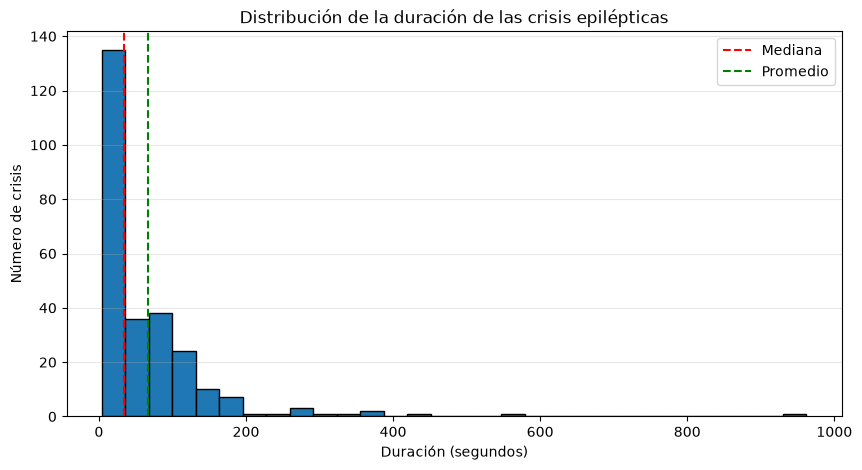

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(
    df_duraciones["duration"],
    bins=30,
    edgecolor="black"
)

plt.axvline(
    df_duraciones["duration"].median(),
    color="red",
    linestyle="--",
    label="Mediana"
)

plt.axvline(
    df_duraciones["duration"].mean(),
    color="green",
    linestyle="--",
    label="Promedio"
)

plt.title("Distribución de la duración de las crisis epilépticas")
plt.xlabel("Duración (segundos)")
plt.ylabel("Número de crisis")
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.show()

#### Interpretación del histograma

El histograma muestra que la mayor parte de las crisis epilépticas registradas presenta duraciones relativamente cortas, mientras que un número reducido de eventos tiene duraciones considerablemente mayores.

La distribución presenta asimetría hacia la derecha, con una mediana de 34.50 segundos y un promedio de 66.66 segundos. Esta diferencia indica que las crisis de mayor duración influyen en el promedio.

También se observan valores alejados de la concentración principal de los datos, incluido un evento con duración de 962 segundos.

Por lo tanto, la mediana y los percentiles permiten complementar el promedio y describir de manera más adecuada las duraciones registradas.

### 11.2 Distribución de crisis por participante

Se presenta una gráfica de barras con el número de crisis epilépticas registradas por participante.

Esta visualización permite comparar la cantidad de eventos anotados e identificar diferencias entre los participantes del conjunto de datos.

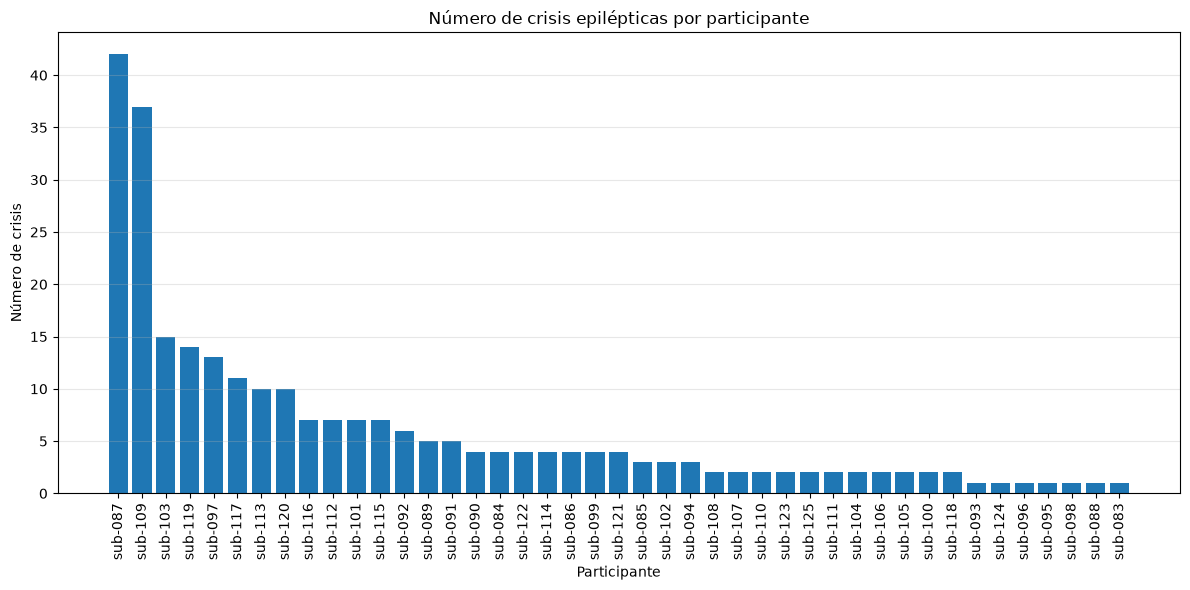

In [19]:
# Consultar el número de crisis por participante
pipeline = [
    {
        "$match": {
            "eventType": {"$regex": "^sz_"}
        }
    },
    {
        "$group": {
            "_id": "$participant_id",
            "numero_crisis": {"$sum": 1}
        }
    },
    {
        "$sort": {"numero_crisis": -1}
    }
]

resultado = list(db["eventos"].aggregate(pipeline))

df_crisis_participante = pd.DataFrame(resultado).rename(
    columns={"_id": "participante"}
)

# Generar gráfica
plt.figure(figsize=(12, 6))

plt.bar(
    df_crisis_participante["participante"],
    df_crisis_participante["numero_crisis"]
)

plt.title("Número de crisis epilépticas por participante")
plt.xlabel("Participante")
plt.ylabel("Número de crisis")

plt.xticks(rotation=90)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

#### Interpretación de la gráfica

La gráfica muestra diferencias importantes en el número de crisis epilépticas registradas por participante.

Los participantes `sub-087` y `sub-109` presentan las cantidades más elevadas, con 42 y 37 crisis, respectivamente. En conjunto, concentran aproximadamente el 30.2 % de las 262 crisis identificadas.

En contraste, la mayoría de los participantes presenta cantidades considerablemente menores, y siete de ellos tienen una sola crisis registrada.

Esta distribución desigual es relevante para los análisis posteriores, ya que algunos participantes aportan más eventos que otros. Sin embargo, estas diferencias no necesariamente representan una mayor frecuencia de crisis, debido a que también pueden depender del tiempo de monitoreo disponible para cada participante.

### 11.3 Distribución de los tipos de crisis epilépticas

Se presenta una gráfica de barras horizontales para visualizar la cantidad de crisis registradas según su clasificación en el atributo `eventType`.

Esta representación permite identificar los tipos de crisis más frecuentes y comparar su presencia dentro del conjunto de datos.

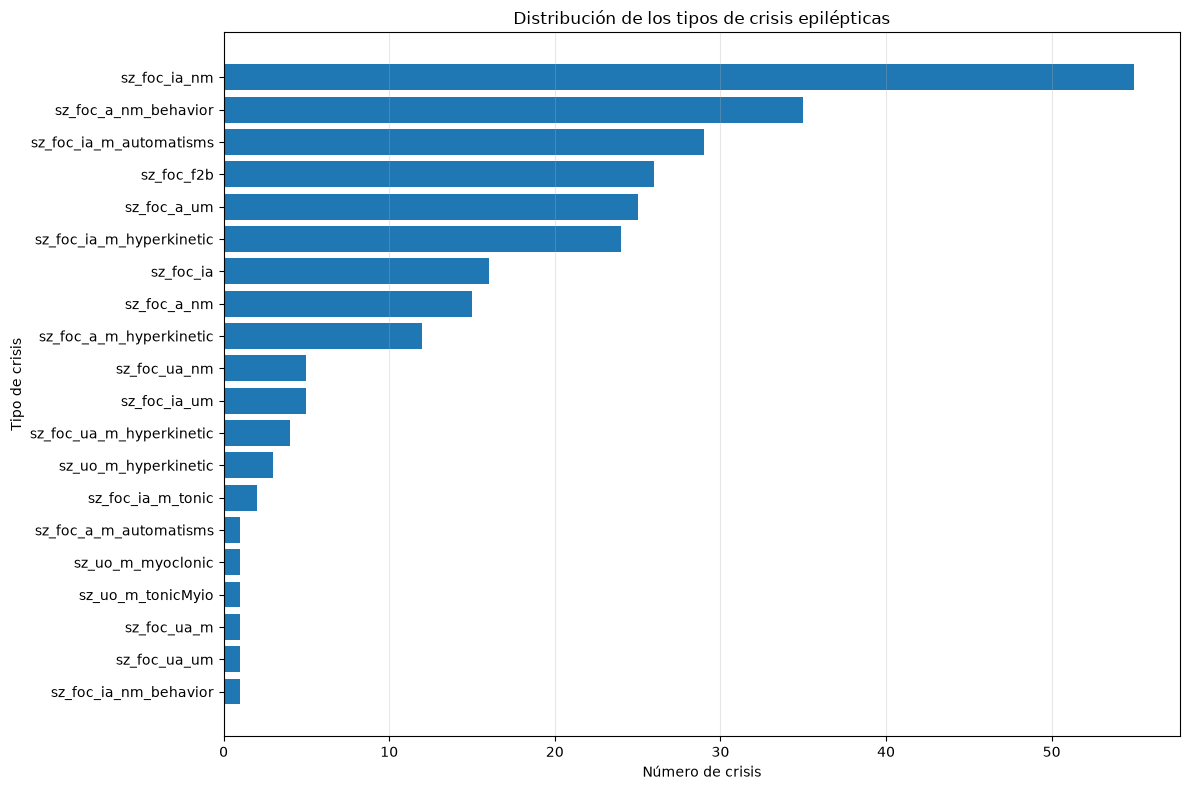

In [20]:
pipeline_tipos = [
    {
        "$match": {
            "eventType": {"$regex": "^sz_"}
        }
    },
    {
        "$group": {
            "_id": "$eventType",
            "numero_crisis": {"$sum": 1}
        }
    },
    {
        "$sort": {"numero_crisis": -1}
    }
]

resultado_tipos = list(db["eventos"].aggregate(pipeline_tipos))

df_tipos = pd.DataFrame(resultado_tipos).rename(
    columns={"_id": "tipo_crisis"}
)

# Ordenar para mostrar las categorías más frecuentes arriba
df_grafica = df_tipos.sort_values("numero_crisis")

plt.figure(figsize=(12, 8))

plt.barh(
    df_grafica["tipo_crisis"],
    df_grafica["numero_crisis"]
)

plt.title("Distribución de los tipos de crisis epilépticas")
plt.xlabel("Número de crisis")
plt.ylabel("Tipo de crisis")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

#### Interpretación de la gráfica

La gráfica muestra la distribución de las 262 crisis epilépticas según las 20 clasificaciones identificadas en el conjunto de datos.

La categoría más frecuente es `sz_foc_ia_nm`, correspondiente a crisis focales con alteración de la conciencia y sin manifestaciones motoras, con 55 registros (20.99 %). Le siguen `sz_foc_a_nm_behavior`, con 35 registros (13.36 %), y `sz_foc_ia_m_automatisms`, con 29 registros (11.07 %).

Las cinco categorías más frecuentes concentran aproximadamente el 64.89 % de las crisis registradas.

También se observa que algunas clasificaciones tienen solamente uno o dos registros, lo que evidencia una distribución desigual entre los tipos de crisis.

Esta diferencia es importante para análisis posteriores, ya que las categorías con pocos registros podrían dificultar las comparaciones y el entrenamiento de modelos de aprendizaje automático.

### 11.4 Disponibilidad de modalidades de registro

Se analiza la cantidad de grabaciones disponibles según su modalidad: electroencefalografía (EEG), electrocardiografía (ECG), electromiografía (EMG) y movimiento (MOV).

Esta exploración permite conocer la disponibilidad de los distintos tipos de registros fisiológicos y de movimiento que podrían utilizarse posteriormente para estudiar los periodos previos a las crisis epilépticas.

,modalidad,numero_grabaciones
0,eeg,1730
1,emg,1708
2,ecg,1708
3,mov,1564


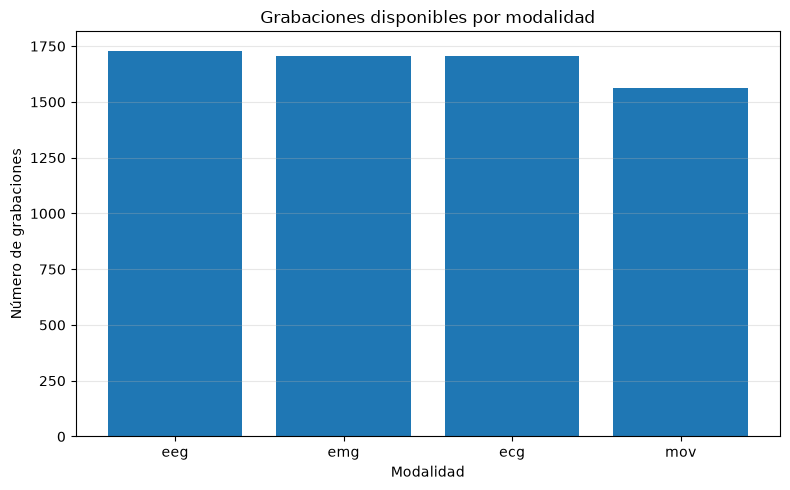

In [21]:
pipeline_modalidades = [
    {
        "$group": {
            "_id": "$modality",
            "numero_grabaciones": {"$sum": 1}
        }
    },
    {
        "$sort": {"numero_grabaciones": -1}
    }
]

resultado_modalidades = list(
    db["grabaciones"].aggregate(pipeline_modalidades)
)

df_modalidades = pd.DataFrame(resultado_modalidades).rename(
    columns={"_id": "modalidad"}
)

display(df_modalidades)

plt.figure(figsize=(8, 5))

plt.bar(
    df_modalidades["modalidad"],
    df_modalidades["numero_grabaciones"]
)

plt.title("Grabaciones disponibles por modalidad")
plt.xlabel("Modalidad")
plt.ylabel("Número de grabaciones")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

#### Interpretación de la gráfica

Se identificaron 6,710 registros de grabaciones distribuidos en cuatro modalidades: EEG, EMG, ECG y MOV.

La modalidad con mayor cantidad de registros fue EEG, con 1,730 grabaciones, seguida de EMG y ECG, ambas con 1,708. La modalidad MOV presentó la menor cantidad, con 1,564 registros.

Aunque las cuatro modalidades están representadas, existen diferencias en su disponibilidad. Esto es importante para la investigación, ya que el análisis de los periodos previos a las crisis requiere identificar qué señales están disponibles para cada evento.

Estos resultados describen la disponibilidad de los archivos registrados en MongoDB, pero todavía no permiten determinar qué cambios fisiológicos ocurren antes de una crisis epiléptica.

### 11.5 Disponibilidad de modalidades en grabaciones con crisis

Se realiza una agregación de MongoDB para relacionar las anotaciones de crisis epilépticas con los metadatos de las grabaciones.

La relación se establece mediante los atributos `participant_id`, `session` y `run`, que permiten identificar los segmentos donde se registraron las crisis.

El objetivo es conocer cuántos segmentos con crisis cuentan con registros EEG, ECG, EMG y MOV, como una primera aproximación a la disponibilidad de información para el análisis de periodos previos a las crisis.

In [22]:
pipeline_crisis_modalidades = [
    # Seleccionar únicamente las crisis
    {
        "$match": {
            "eventType": {"$regex": "^sz_"}
        }
    },

    # Obtener segmentos únicos con al menos una crisis
    {
        "$group": {
            "_id": {
                "participant_id": "$participant_id",
                "session": "$session",
                "run": "$run"
            }
        }
    },

    # Relacionar los segmentos con sus grabaciones
    {
        "$lookup": {
            "from": "grabaciones",
            "let": {
                "pid": "$_id.participant_id",
                "ses": "$_id.session",
                "run": "$_id.run"
            },
            "pipeline": [
                {
                    "$match": {
                        "$expr": {
                            "$and": [
                                {"$eq": ["$participant_id", "$$pid"]},
                                {"$eq": ["$session", "$$ses"]},
                                {"$eq": ["$run", "$$run"]}
                            ]
                        }
                    }
                }
            ],
            "as": "grabaciones_asociadas"
        }
    },

    # Separar las grabaciones por modalidad
    {
        "$unwind": "$grabaciones_asociadas"
    },

    # Contar grabaciones asociadas
    {
        "$group": {
            "_id": "$grabaciones_asociadas.modality",
            "numero_grabaciones": {"$sum": 1}
        }
    },

    {
        "$sort": {"numero_grabaciones": -1}
    }
]

resultado = list(
    db["eventos"].aggregate(pipeline_crisis_modalidades)
)

df_modalidades_crisis = pd.DataFrame(resultado).rename(
    columns={"_id": "modalidad"}
)

display(df_modalidades_crisis)

,modalidad,numero_grabaciones
0,eeg,153
1,ecg,145
2,emg,145
3,mov,113


#### Interpretación de los resultados

Mediante una agregación de MongoDB se relacionaron las colecciones `eventos` y `grabaciones`, utilizando los atributos `participant_id`, `session` y `run`.

Se identificaron 153 grabaciones EEG, 145 ECG, 145 EMG y 113 MOV asociadas con segmentos donde se registró al menos una crisis epiléptica.

La modalidad EEG presentó la mayor disponibilidad, mientras que MOV tuvo la menor cantidad de registros asociados.

Estas diferencias indican que no todas las modalidades están disponibles en todos los segmentos con crisis, lo cual es relevante para el análisis posterior de señales fisiológicas.

Los resultados permiten identificar la disponibilidad de archivos asociados con crisis, pero no muestran todavía cambios fisiológicos previos a los eventos.

### 11.6 Disponibilidad conjunta de modalidades

Se analiza cuántos segmentos con crisis epilépticas cuentan con las cuatro modalidades de registro disponibles.

El objetivo es identificar segmentos que podrían utilizarse posteriormente para estudiar conjuntamente señales cerebrales, cardíacas, musculares y de movimiento durante los periodos previos a las crisis.

In [23]:
pipeline_conjunto = [
    {
        "$match": {
            "eventType": {"$regex": "^sz_"}
        }
    },
    {
        "$group": {
            "_id": {
                "participant_id": "$participant_id",
                "session": "$session",
                "run": "$run"
            }
        }
    },
    {
        "$lookup": {
            "from": "grabaciones",
            "let": {
                "pid": "$_id.participant_id",
                "ses": "$_id.session",
                "run": "$_id.run"
            },
            "pipeline": [
                {
                    "$match": {
                        "$expr": {
                            "$and": [
                                {"$eq": ["$participant_id", "$$pid"]},
                                {"$eq": ["$session", "$$ses"]},
                                {"$eq": ["$run", "$$run"]}
                            ]
                        }
                    }
                }
            ],
            "as": "grabaciones"
        }
    },
    {
        "$project": {
            "modalidades": "$grabaciones.modality"
        }
    },
    {
        "$project": {
            "tiene_cuatro_modalidades": {
                "$setIsSubset": [
                    ["eeg", "ecg", "emg", "mov"],
                    "$modalidades"
                ]
            }
        }
    },
    {
        "$group": {
            "_id": "$tiene_cuatro_modalidades",
            "numero_segmentos": {"$sum": 1}
        }
    }
]

resultado_conjunto = list(
    db["eventos"].aggregate(pipeline_conjunto)
)

df_conjunto = pd.DataFrame(resultado_conjunto).rename(
    columns={
        "_id": "cuatro_modalidades",
        "numero_segmentos": "segmentos"
    }
)

df_conjunto["cuatro_modalidades"] = (
    df_conjunto["cuatro_modalidades"].map({
        True: "Sí",
        False: "No"
    })
)

display(df_conjunto)

,cuatro_modalidades,segmentos
0,No,48
1,Sí,105


#### Interpretación de los resultados

Se identificaron 153 segmentos de grabación con al menos una crisis epiléptica registrada.

De estos, 105 segmentos (68.63 %) cuentan con las cuatro modalidades: EEG, ECG, EMG y MOV. Los 48 segmentos restantes (31.37 %) no tienen disponibles todas las modalidades.

Estos resultados muestran que una parte importante de los segmentos con crisis podría utilizarse para un análisis conjunto de diferentes señales fisiológicas y de movimiento.

Sin embargo, la disponibilidad de los archivos no garantiza que todos contengan información suficiente del periodo previo a una crisis. Para determinarlo, será necesario revisar el momento de inicio de cada evento y la duración del registro disponible.

### 11.7 Disponibilidad temporal antes de las crisis

Se analiza el tiempo disponible antes del inicio de las crisis epilépticas utilizando el atributo `onset`.

Se consideran tres ventanas temporales de referencia: 5, 10 y 30 minutos antes de cada crisis.

El objetivo es identificar cuántas anotaciones de crisis cuentan con suficiente tiempo de grabación anterior a su inicio dentro del mismo segmento.

Este análisis permite evaluar preliminarmente la disponibilidad temporal de los registros para estudiar posibles cambios fisiológicos previos a una crisis.

In [24]:
pipeline_ventanas = [
    {
        "$match": {
            "eventType": {"$regex": "^sz_"},
            "onset": {"$type": "number"}
        }
    },
    {
        "$group": {
            "_id": None,
            "total_crisis": {"$sum": 1},
            "ventana_5_min": {
                "$sum": {
                    "$cond": [{"$gte": ["$onset", 300]}, 1, 0]
                }
            },
            "ventana_10_min": {
                "$sum": {
                    "$cond": [{"$gte": ["$onset", 600]}, 1, 0]
                }
            },
            "ventana_30_min": {
                "$sum": {
                    "$cond": [{"$gte": ["$onset", 1800]}, 1, 0]
                }
            }
        }
    },
    {
        "$project": {
            "_id": 0,
            "total_crisis": 1,
            "ventana_5_min": 1,
            "ventana_10_min": 1,
            "ventana_30_min": 1
        }
    }
]

resultado_ventanas = list(
    db["eventos"].aggregate(pipeline_ventanas)
)

display(pd.DataFrame(resultado_ventanas))

,total_crisis,ventana_5_min,ventana_10_min,ventana_30_min
0,262,240,230,191


#### Interpretación de los resultados

Se analizaron 262 anotaciones de crisis epilépticas para determinar la disponibilidad temporal anterior a su inicio dentro del segmento de grabación.

Los resultados muestran que 240 crisis (91.60 %) tienen al menos 5 minutos de registro previo, 230 (87.79 %) cuentan con al menos 10 minutos y 191 (72.90 %) presentan al menos 30 minutos.

Estos resultados indican que una proporción importante de las crisis dispone de tiempo de grabación anterior a su inicio, lo que representa una oportunidad para estudiar posibles cambios fisiológicos durante el periodo previo.

No obstante, esta evaluación considera únicamente el tiempo disponible según el atributo `onset`. Todavía es necesario verificar si las ventanas contienen otras crisis y si las señales fisiológicas están disponibles y tienen calidad suficiente.

### 11.8 Ventanas previas sin superposición con otras crisis

Se evalúa la disponibilidad de ventanas temporales anteriores a las crisis epilépticas, considerando la posible superposición con eventos de crisis previos dentro del mismo segmento de grabación.

Para cada crisis se calcula el tiempo transcurrido desde el final de la crisis anterior, cuando existe, y se determina si pueden seleccionarse ventanas de 5, 10 y 30 minutos sin superposición con otra crisis anotada.

Este análisis permite identificar ventanas temporalmente más adecuadas para una futura exploración de las señales fisiológicas previas a las crisis.

In [25]:
# Recuperar las crisis con sus tiempos de inicio y duración
pipeline_crisis = [
    {
        "$match": {
            "eventType": {"$regex": "^sz_"},
            "onset": {"$type": "number"},
            "duration": {"$type": "number"}
        }
    },
    {
        "$project": {
            "_id": 0,
            "participant_id": 1,
            "session": 1,
            "run": 1,
            "onset": 1,
            "duration": 1
        }
    },
    {
        "$sort": {
            "participant_id": 1,
            "session": 1,
            "run": 1,
            "onset": 1
        }
    }
]

df_eventos_crisis = pd.DataFrame(
    list(db["eventos"].aggregate(pipeline_crisis))
)

# Calcular el tiempo disponible sin crisis anteriores
columnas_grupo = ["participant_id", "session", "run"]

df_eventos_crisis["fin_crisis"] = (
    df_eventos_crisis["onset"] +
    df_eventos_crisis["duration"]
)

# Máximo tiempo de finalización de las crisis anteriores
df_eventos_crisis["fin_previo"] = (
    df_eventos_crisis.groupby(columnas_grupo)["fin_crisis"]
    .transform(lambda x: x.cummax().shift(1))
)

df_eventos_crisis["inicio_libre"] = (
    df_eventos_crisis["fin_previo"].fillna(0)
)

df_eventos_crisis["tiempo_libre_previo"] = (
    df_eventos_crisis["onset"] -
    df_eventos_crisis["inicio_libre"]
)

# Evaluar ventanas temporales
resumen_ventanas = []

for minutos in [5, 10, 30]:
    segundos = minutos * 60

    disponibles = (
        df_eventos_crisis["tiempo_libre_previo"] >= segundos
    ).sum()

    resumen_ventanas.append({
        "ventana": f"{minutos} minutos",
        "crisis_con_ventana": int(disponibles),
        "porcentaje": round(
            disponibles / len(df_eventos_crisis) * 100, 2
        )
    })

df_resumen_ventanas = pd.DataFrame(resumen_ventanas)

display(df_resumen_ventanas)

,ventana,crisis_con_ventana,porcentaje
0,5 minutos,233,88.93
1,10 minutos,205,78.24
2,30 minutos,133,50.76


#### Interpretación de los resultados

Se evaluó la disponibilidad de ventanas temporales anteriores a las crisis epilépticas, considerando la posible superposición con otras crisis anotadas dentro del mismo segmento de grabación.

De las 262 crisis identificadas, 233 (88.93 %) cuentan con una ventana de 5 minutos sin superposición, 205 (78.24 %) con una ventana de 10 minutos y 133 (50.76 %) con una ventana de 30 minutos.

Al comparar estos resultados con la disponibilidad temporal inicial, se observa una reducción de 7, 25 y 58 crisis, respectivamente.

Esta diferencia muestra la importancia de considerar las crisis anteriores al seleccionar ventanas para el análisis de señales fisiológicas.

Los resultados constituyen una primera aproximación para identificar periodos de interés. Sin embargo, todavía es necesario comprobar la disponibilidad y calidad de las señales, así como establecer criterios para distinguir los periodos previos a las crisis de los periodos de referencia.

### 11.9 Comparación de la disponibilidad de ventanas temporales

Se comparan las ventanas temporales inicialmente disponibles con aquellas que no presentan superposición con otras crisis anotadas dentro del mismo segmento de grabación.

Esta visualización permite identificar cómo disminuye la cantidad de eventos disponibles al incorporar un criterio adicional de selección, considerando ventanas de 5, 10 y 30 minutos anteriores al inicio de las crisis.

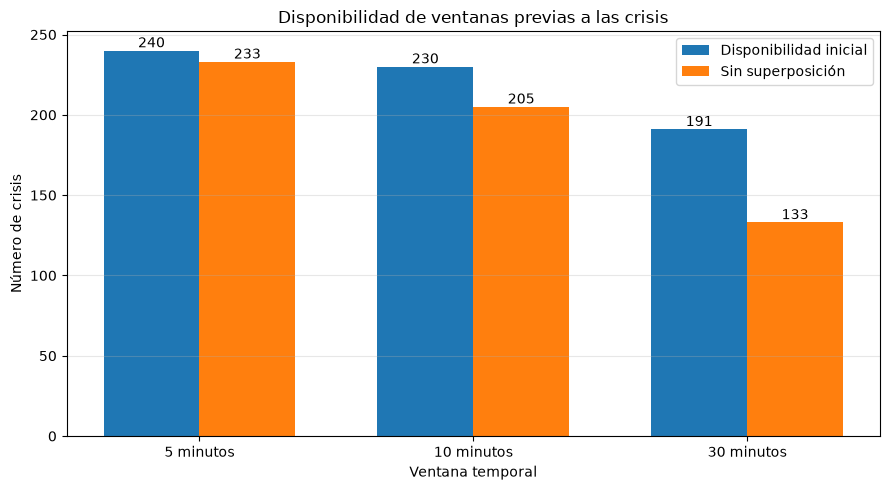

In [26]:
import numpy as np
import matplotlib.pyplot as plt

# Resultados obtenidos en los apartados 11.7 y 11.8
ventanas = ["5 minutos", "10 minutos", "30 minutos"]

disponibilidad_inicial = [240, 230, 191]
sin_superposicion = [233, 205, 133]

# Posiciones de las barras
x = np.arange(len(ventanas))
ancho = 0.35

fig, ax = plt.subplots(figsize=(9, 5))

barras1 = ax.bar(
    x - ancho / 2,
    disponibilidad_inicial,
    ancho,
    label="Disponibilidad inicial"
)

barras2 = ax.bar(
    x + ancho / 2,
    sin_superposicion,
    ancho,
    label="Sin superposición"
)

ax.set_title("Disponibilidad de ventanas previas a las crisis")
ax.set_xlabel("Ventana temporal")
ax.set_ylabel("Número de crisis")

ax.set_xticks(x)
ax.set_xticklabels(ventanas)

ax.legend()
ax.grid(axis="y", alpha=0.3)

# Mostrar valores sobre las barras
ax.bar_label(barras1)
ax.bar_label(barras2)

plt.tight_layout()
plt.show()

#### Interpretación de la gráfica

La gráfica compara la disponibilidad inicial de ventanas temporales con aquellas que no presentan superposición con otras crisis anotadas dentro del mismo segmento de grabación.

Para ventanas de 5 minutos, la cantidad disminuyó de 240 a 233 crisis; para ventanas de 10 minutos, de 230 a 205; y para ventanas de 30 minutos, de 191 a 133.

Se observa que la reducción es mayor conforme aumenta la duración de la ventana temporal. Esto indica que seleccionar periodos más largos sin superposición con otras crisis resulta más restrictivo.

Estos resultados son relevantes para la investigación porque muestran que la duración de la ventana temporal influye en la cantidad de eventos disponibles para un análisis posterior de señales fisiológicas.

Sin embargo, la selección definitiva de ventanas también deberá considerar la disponibilidad y calidad de las señales, así como la posible influencia de crisis ocurridas en segmentos anteriores.

## 12. Hallazgos del análisis exploratorio

El análisis exploratorio de la base de datos SeizeIT2 permitió identificar los siguientes hallazgos:

1. **Distribución de las crisis:** Se identificaron 262 anotaciones de crisis epilépticas distribuidas entre 43 participantes. La cantidad de crisis no fue uniforme, ya que algunos participantes concentraron un mayor número de eventos.

2. **Duración de las crisis:** La duración promedio fue de 66.66 segundos y la mediana de 34.50 segundos. La distribución presentó asimetría hacia la derecha, debido a la presencia de crisis de duración elevada.

3. **Tipos de crisis:** Se identificaron 20 clasificaciones, con diferencias importantes en su frecuencia. Las cinco categorías más frecuentes concentraron aproximadamente el 64.89 % de las anotaciones.

4. **Disponibilidad de modalidades:** Se registraron 6,710 grabaciones correspondientes a EEG, ECG, EMG y MOV. De los 153 segmentos con crisis, 105 contaron con las cuatro modalidades.

5. **Disponibilidad temporal:** De las 262 crisis, 240 tenían al menos 5 minutos de registro previo, 230 tenían 10 minutos y 191 tenían 30 minutos.

6. **Ventanas sin superposición:** Al considerar otras crisis anotadas dentro del mismo segmento, las cantidades disminuyeron a 233, 205 y 133 eventos para ventanas de 5, 10 y 30 minutos, respectivamente.

### Limitaciones del análisis

Los resultados se obtuvieron a partir de los metadatos de las grabaciones y las anotaciones de eventos almacenados en MongoDB.

No se analizaron directamente las señales fisiológicas contenidas en los archivos EDF, por lo que todavía no es posible identificar patrones preictales ni evaluar su capacidad predictiva.

Además, las ventanas temporales se evaluaron dentro de cada segmento, sin comprobar la continuidad con grabaciones anteriores. Tampoco se ha evaluado la calidad de las señales ni la independencia de los eventos registrados por un mismo participante.